<a href="https://colab.research.google.com/github/tahiyat-rafi/Introduction-to-deep-learning-/blob/main/visual_output_of_2D_wave_equation_PINN_(oop).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

epoch:    0, loss: 0.016017
epoch:  200, loss: 0.000000
epoch:  400, loss: 0.000000
epoch:  600, loss: 0.000000
epoch:  800, loss: 0.000000
Training Completed



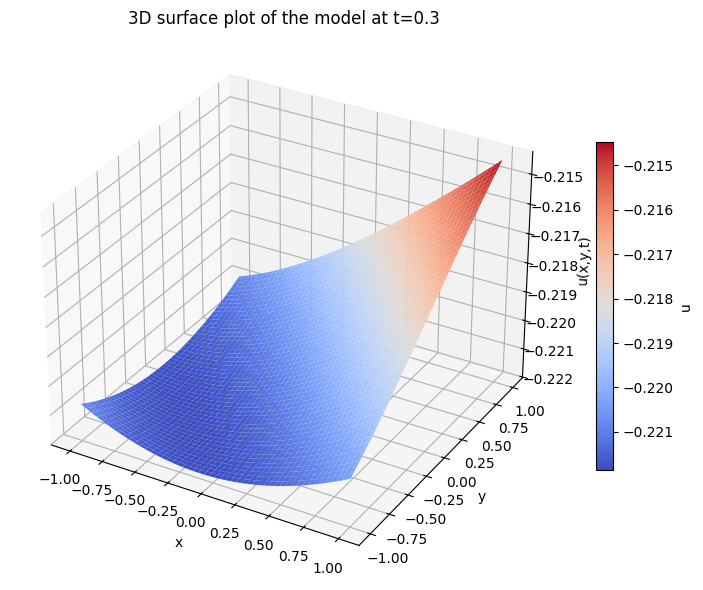

In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import plotly.graph_objects as go

#pde: u_tt = c**2*(u_xx + u_yy)
#class
class pinn(nn.Module):
  def __init__(self,hidden_dim=32,c = 1.0,lr=.001):
      super().__init__()
      self.c = c

      self.net = nn.Sequential(
      nn.Linear(3,hidden_dim),
      nn.Tanh(),
      nn.Linear(hidden_dim,hidden_dim),
      nn.Tanh(),
      nn.Linear(hidden_dim,hidden_dim),
      nn.Tanh(),
      nn.Linear(hidden_dim,1)
         )

      #optimizer
      self.optimizer = torch.optim.Adam(self.parameters(),lr=lr)

  def forward(self,x,y,t):
      inputs = torch.cat([x,y,t], dim=1)
      return self.net(inputs)

        #loss function
  def loss(self,x,y,t):
      x.requires_grad=True
      y.requires_grad=True
      t.requires_grad=True
      u = self.forward(x,y,t)
      #df
      u_x = torch.autograd.grad(u,x,grad_outputs=torch.ones_like(u),create_graph=True)[0]
      u_y = torch.autograd.grad(u,y,grad_outputs=torch.ones_like(u),create_graph=True)[0]
      u_t = torch.autograd.grad(u,t,grad_outputs=torch.ones_like(u),create_graph=True)[0]
      #ddf
      u_xx = torch.autograd.grad(u_x,x,grad_outputs=torch.ones_like(u_x),create_graph=True)[0]
      u_yy = torch.autograd.grad(u_y,y,grad_outputs=torch.ones_like(u_y),create_graph=True)[0]
      u_tt = torch.autograd.grad(u_t,t,grad_outputs=torch.ones_like(u_t),create_graph=True)[0]
      err = u_tt-(self.c**2)*(u_xx+u_yy)
      return torch.mean(err**2)

        #training
  def train_model(self,epochs=1000,points=500):
      for epoch in range(epochs):
        self.optimizer.zero_grad()
        x = torch.rand(points,1)*2-1
        y = torch.rand(points,1)*2-1
        t = torch.rand(points,1)*1

        loss_val = self.loss(x,y,t)
        loss_val.backward()
        self.optimizer.step()

        if epoch % 200 == 0:
          print(f"epoch: {epoch:4d}, loss: {loss_val.item():.6f}")
      print("Training Completed\n")

      #plotting function
def surf_plot_3D(model, t_val=0.2, grid_n=300):
      model.eval()

      #inputs
      vals = torch.linspace(-1.0,1.0,grid_n)
      X,Y  = torch.meshgrid(vals,vals,indexing="ij")
      x_col = X.reshape(-1,1)
      y_col = Y.reshape(-1,1)
      t_col = torch.full_like(x_col,t_val)

      with torch.no_grad():
        U = model.forward(x_col, y_col, t_col).reshape(grid_n,grid_n)

      #creating figure
      fig = plt.figure(figsize=(8, 6))
      ax1 = fig.add_subplot(111,projection="3d")
      surf = ax1.plot_surface(X.numpy(), Y.numpy(), U.numpy(), cmap="coolwarm",edgecolor="none")

      #labeling and legend
      ax1.set_xlabel("x")
      ax1.set_ylabel("y")
      ax1.set_zlabel("u(x,y,t)")
      ax1.set_title(f"3D surface plot of the model at t={t_val}")
      fig.colorbar(surf, ax=ax1, shrink=0.6,label="u")

      #trainting saving and output
      plt.tight_layout()
      plt.savefig("PINN_model_3D_surface.png",dpi=400)
      plt.show()

def interactive_surf_plot(model, t_val=.3, grid_n=50):
    model.eval()

    #inputs
    vals = torch.linspace(-1.0,1.0,grid_n)
    X,Y  = torch.meshgrid(vals,vals,indexing="ij")
    x_col = X.reshape(-1,1)
    y_col = Y.reshape(-1,1)
    t_col = torch.full_like(x_col,t_val)

    with torch.no_grad():
      U = model.forward(x_col, y_col, t_col).reshape(grid_n,grid_n)

    fig = go.Figure(data=[
                go.Surface(x=X.numpy(),y=Y.numpy(),z=U.numpy(),colorscale="RdBu_r",colorbar=dict(title="u"))])
    fig.update_layout(title=f"3D surface plot of the model at t={t_val}",
                scene=dict(xaxis_title="x",yaxis_title="y",zaxis_title="u(x,y,t)"),width=800,height=600)
    fig.show()

#execution
if __name__ == "__main__":
  model1 = pinn(hidden_dim=32, c=1.5, lr=0.006)
  model1.train_model(epochs=1000, points=2000)
  interactive_surf_plot(model1, t_val=0.3, grid_n=100)
  surf_plot_3D(model1, t_val=0.3, grid_n=100)

